Praktikum 4 - Klasifikasi Citra Wajah (Labeled Faces in the Wild / LFW).

Pipeline: fetch_lfw_people(min_faces_per_person=60) -> PCA(150, whiten) ->
SVC RBF(class_weight='balanced') -> GridSearchCV(C, gamma) -> evaluasi
classification_report + confusion matrix + visualisasi prediksi.

Dataset diunduh sekali dari sklearn (butuh internet pada run pertama,
tersimpan di ~/scikit_learn_data). Grid 4x4 dengan cv=3 (modul memakai cv=5
default) supaya script selesai < 2 menit.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("wajah_pca_svm.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js11-klasifikasi-2\praktikum-4


In [2]:
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_lfw_people
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)

t0 = time.time()
faces = fetch_lfw_people(min_faces_per_person=60)
print(f"[data] n_samples={faces.images.shape[0]} "
      f"image_shape={faces.images.shape[1:]} n_features={faces.data.shape[1]}")
print(f"[data] jumlah kelas={len(faces.target_names)}: {[str(n) for n in faces.target_names]}")
print("[data] jumlah citra per orang: "
      f"{ {str(n): int(c) for n, c in zip(faces.target_names, np.bincount(faces.target))} }")
print(f"[data] waktu muat = {time.time() - t0:.1f}s (cache lokal, unduh hanya run pertama)")

[data] n_samples=1348 image_shape=(62, 47) n_features=2914
[data] jumlah kelas=8: ['Ariel Sharon', 'Colin Powell', 'Donald Rumsfeld', 'George W Bush', 'Gerhard Schroeder', 'Hugo Chavez', 'Junichiro Koizumi', 'Tony Blair']
[data] jumlah citra per orang: {'Ariel Sharon': 77, 'Colin Powell': 236, 'Donald Rumsfeld': 121, 'George W Bush': 530, 'Gerhard Schroeder': 109, 'Hugo Chavez': 71, 'Junichiro Koizumi': 60, 'Tony Blair': 144}
[data] waktu muat = 0.2s (cache lokal, unduh hanya run pertama)


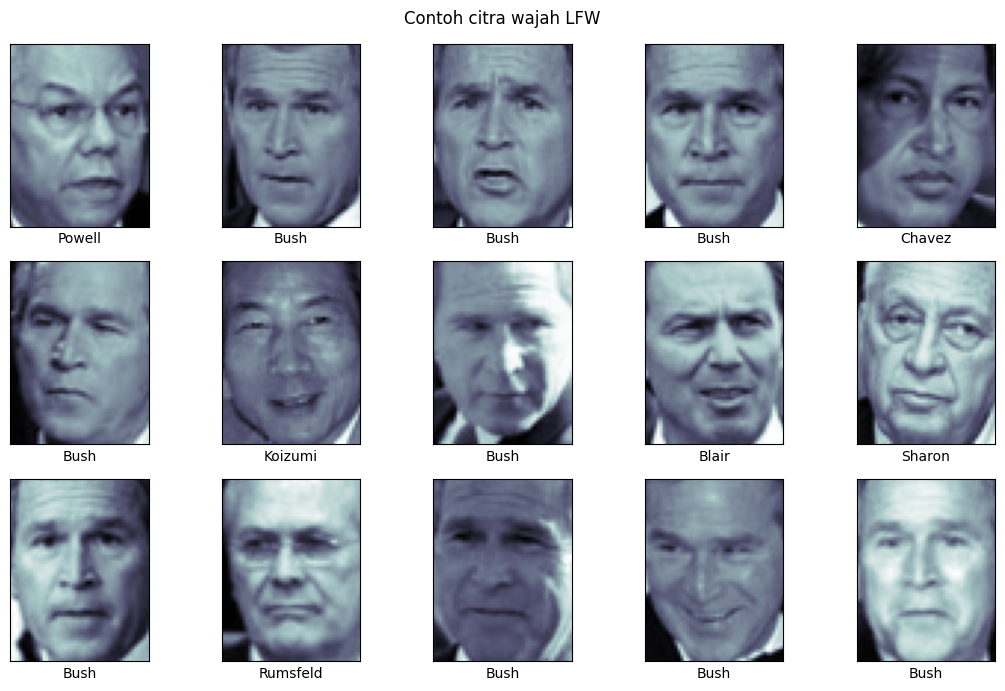

In [3]:
# --- Langkah 1: inspeksi citra -------------------------------------------
fig, ax = plt.subplots(3, 5, figsize=(11, 7))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap="bone")
    axi.set(xticks=[], yticks=[], xlabel=faces.target_names[faces.target[i]].split()[-1])
fig.suptitle("Contoh citra wajah LFW")
fig.tight_layout()
fig.savefig(OUT / "01_contoh_wajah.png", dpi=100)

In [4]:
# --- Langkah 2-3: pipeline PCA+SVC, split ---------------------------------
pca = PCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel="rbf", class_weight="balanced")
model = make_pipeline(pca, svc)
Xtrain, Xtest, ytrain, ytest = train_test_split(
    faces.data, faces.target, random_state=42, stratify=faces.target)
print(f"[split] train={Xtrain.shape} test={Xtest.shape}")

[split] train=(1011, 2914) test=(337, 2914)


In [5]:
# --- Langkah 4: GridSearchCV ---------------------------------------------
param_grid = {"svc__C": [1, 5, 10, 50],
              "svc__gamma": [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid, cv=3, n_jobs=-1)
t1 = time.time()
grid.fit(Xtrain, ytrain)
print(f"[grid] {len(param_grid['svc__C']) * len(param_grid['svc__gamma'])} kombinasi "
      f"x 3-fold selesai dalam {time.time() - t1:.1f}s")
print(f"[grid] best_params = {grid.best_params_}")
print(f"[grid] best_score (cv akurasi) = {grid.best_score_:.4f}")

model = grid.best_estimator_
yfit = model.predict(Xtest)
print(f"[eval] akurasi test = {accuracy_score(ytest, yfit):.4f}")

[grid] 16 kombinasi x 3-fold selesai dalam 13.9s
[grid] best_params = {'svc__C': 5, 'svc__gamma': 0.001}
[grid] best_score (cv akurasi) = 0.8170
[eval] akurasi test = 0.8576


[eval] prediksi salah = 48/337 (14.2%)


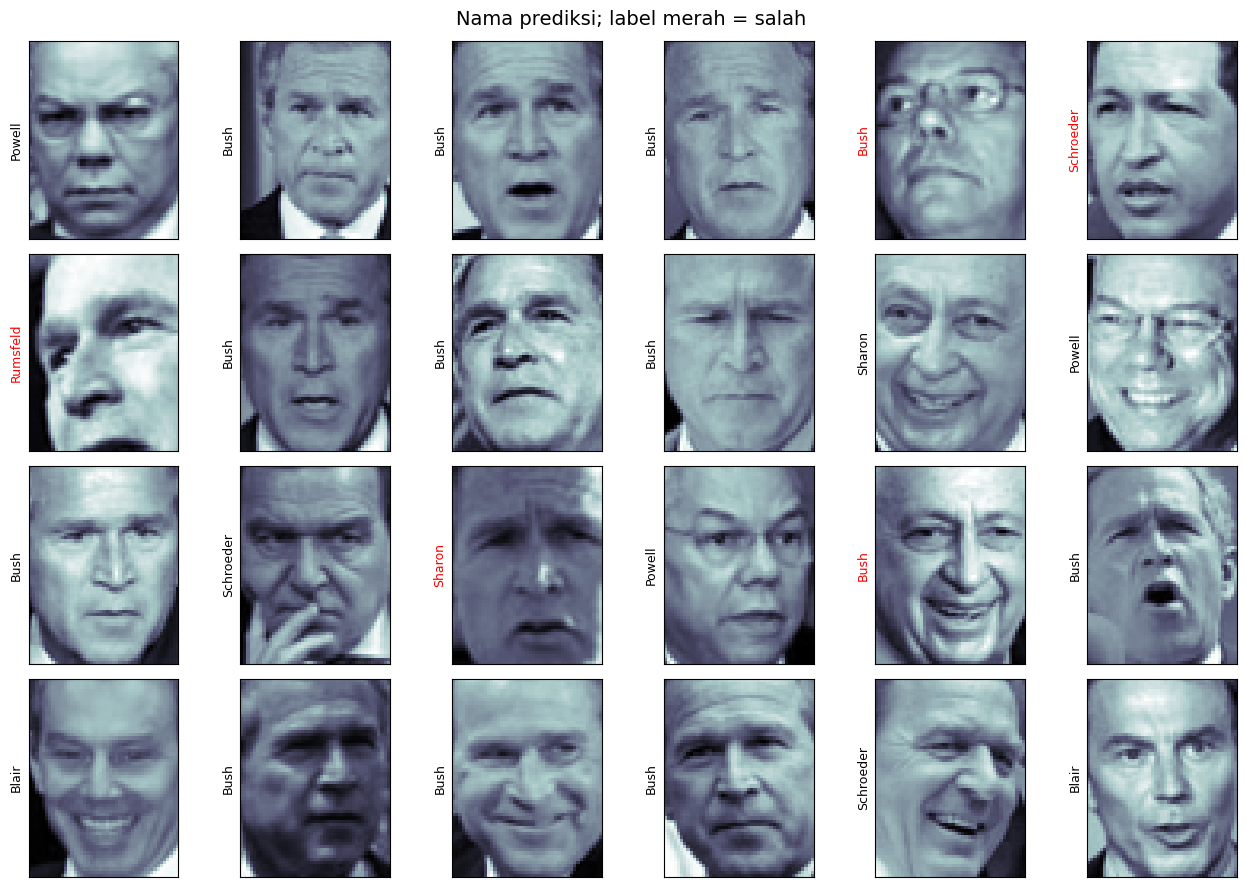

In [6]:
# --- Langkah 5: cek hasil prediksi ---------------------------------------
fig, ax = plt.subplots(4, 6, figsize=(13, 9))
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(faces.images.shape[1:]), cmap="bone")
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color="black" if yfit[i] == ytest[i] else "red", fontsize=9)
fig.suptitle("Nama prediksi; label merah = salah", size=14)
fig.tight_layout()
fig.savefig(OUT / "02_hasil_prediksi.png", dpi=100)
n_wrong = int((yfit != ytest).sum())
print(f"[eval] prediksi salah = {n_wrong}/{len(ytest)} "
      f"({n_wrong / len(ytest) * 100:.1f}%)")


=== classification_report ===
                   precision    recall  f1-score   support

     Ariel Sharon     0.7222    0.6842    0.7027        19
     Colin Powell     0.8060    0.9153    0.8571        59
  Donald Rumsfeld     0.8333    0.8333    0.8333        30
    George W Bush     0.9231    0.9023    0.9125       133
Gerhard Schroeder     0.7576    0.9259    0.8333        27
      Hugo Chavez     0.9091    0.5556    0.6897        18
Junichiro Koizumi     0.8462    0.7333    0.7857        15
       Tony Blair     0.8857    0.8611    0.8732        36

         accuracy                         0.8576       337
        macro avg     0.8354    0.8014    0.8110       337
     weighted avg     0.8618    0.8576    0.8559       337

=== confusion matrix (baris=true, kolom=prediksi) ===
[[ 13   2   1   1   2   0   0   0]
 [  2  54   0   2   0   0   0   1]
 [  1   2  25   1   0   1   0   0]
 [  2   6   1 120   1   0   2   1]
 [  0   0   0   1  25   0   0   1]
 [  0   2   0   2   4  10   0

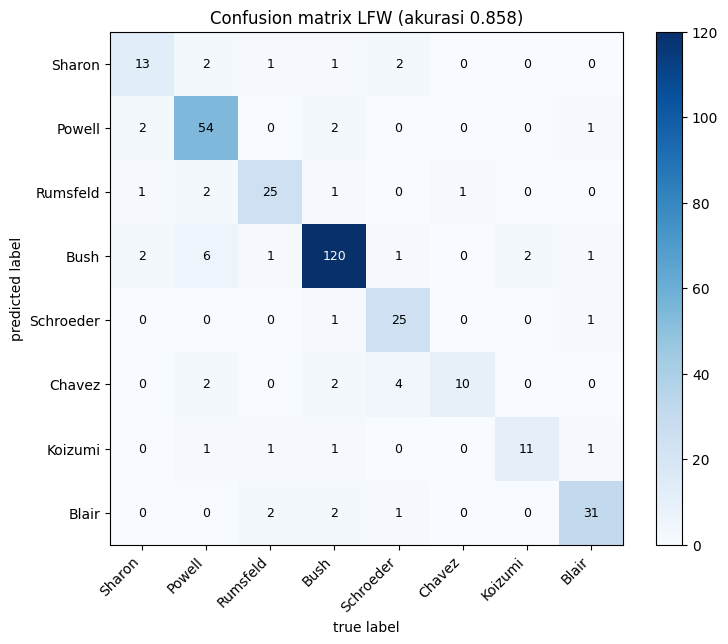

In [7]:
# --- Langkah 6: performansi ----------------------------------------------
print("\n=== classification_report ===")
print(classification_report(ytest, yfit, target_names=faces.target_names, digits=4))

mat = confusion_matrix(ytest, yfit)
print("=== confusion matrix (baris=true, kolom=prediksi) ===")
print(mat)

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(mat, cmap="Blues")
ax.set_xticks(range(len(faces.target_names)),
              [n.split()[-1] for n in faces.target_names], rotation=45, ha="right")
ax.set_yticks(range(len(faces.target_names)),
              [n.split()[-1] for n in faces.target_names])
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, mat[i, j], ha="center", va="center",
                color="w" if mat[i, j] > mat.max() / 2 else "k", fontsize=9)
ax.set(xlabel="true label", ylabel="predicted label",
       title=f"Confusion matrix LFW (akurasi {accuracy_score(ytest, yfit):.3f})")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(OUT / "03_confusion_matrix.png", dpi=110)

In [8]:
# akurasi per kelas
print("=== akurasi per kelas ===")
for i, name in enumerate(faces.target_names):
    mask = ytest == i
    if mask.sum():
        print(f"  {name:<22} {accuracy_score(ytest[mask], yfit[mask]):.4f} "
              f"(n={int(mask.sum())})")
print("[selesai] praktikum 4")

=== akurasi per kelas ===
  Ariel Sharon           0.6842 (n=19)
  Colin Powell           0.9153 (n=59)
  Donald Rumsfeld        0.8333 (n=30)
  George W Bush          0.9023 (n=133)
  Gerhard Schroeder      0.9259 (n=27)
  Hugo Chavez            0.5556 (n=18)
  Junichiro Koizumi      0.7333 (n=15)
  Tony Blair             0.8611 (n=36)
[selesai] praktikum 4
